# Step 9: Key driver analysis

The last question I wanted to answer: which parts of the service matter most to tenants' **overall** satisfaction? The TSM survey asks about overall satisfaction (TP01) and 11 specific things (TP02 to TP12): repairs, safety, being listened to, fair treatment and so on. A **key driver analysis** works out which of the 11 best explain the overall score, and so where a landlord should focus.

Then I combine that **importance** with how the sector actually scores on each measure, to find the sector's biggest opportunities: measures that matter a lot *and* where satisfaction is lowest.

**The tricky part is that the 11 measures overlap a lot.** A landlord that scores well on repairs usually scores well on everything. An ordinary regression can't split the credit fairly between inputs that overlap this much (section 3 shows what goes wrong), so I used **dominance analysis**, which is designed for exactly this problem.

This notebook only needs the TSM file.

## 1. Load the data

In [1]:
import pandas as pd
import numpy as np
# itertools lets me list every possible combination of measures (I need all 2,048 of them in section 4).
import itertools
import matplotlib.pyplot as plt
import os

# Upload button in Colab, or the file's location on my own computer.
try:
    from google.colab import files
    uploaded = files.upload()
    path = list(uploaded.keys())[0]
except ImportError:
    path = "2025_TSM_Full_Data_v1.1_FINAL.xlsx"

In [2]:
# This is the same loading and joining I worked out in notebooks 1 and 2, just copied in
# so this notebook runs on its own. re is Python's library for matching text patterns.
import re

# RSH puts codes like [X] in cells instead of leaving them blank, so I tell pandas to treat
# them as missing: [X] left blank, [Z] not required, [E] excluded, [U] couldn't be calculated.
missing_codes = ["[X]", "[Z]", "[E]", "[U]"]

# The two sheets have their headers on different rows (row 11 and row 10 in Excel).
lcra = pd.read_excel(path, sheet_name="TSM25_LCRA_Perception", header=10, na_values=missing_codes)
mi = pd.read_excel(path, sheet_name="TSM25_Management_Info", header=9, na_values=missing_codes)

# The survey column names are whole sentences ending in a code like (TP01), so I use a pattern
# to find them and keep just the code as the new name.
tp_pattern = r"^Proportion of respondents who report that they are satisfied.*\((TP\d{2})\)\d*$"
rename_map = {}
for col in lcra.columns:
    match = re.match(tp_pattern, col)
    if match:
        rename_map[col] = match.group(1)

# Shorter names for the other columns I use a lot.
rename_map.update({
    "Landlord name": "landlord",                                          # the landlord's name
    "Landlord code": "code",                                              # RSH's unique ID for each landlord
    "Landlord type": "type",                                              # PRP = housing association, LA = council
    "Landlord group size (homes owned, LCRA and LCHO combined)": "size_band",  # size band
    "Landlord predominant region": "region",                              # region
    "Predominant collection method": "method",                            # main survey method
})

# Pick out the 12 TP codes, then rename and keep only the columns I need.
tp_cols = sorted(name for name in rename_map.values() if name.startswith("TP"))
perception = lcra.rename(columns=rename_map)[
    ["landlord", "code", "type", "size_band", "region", "method"] + tp_cols]


# My function for finding exactly one column whose name contains all the bits of text I give it.
# The assert stops everything if it finds none or several, so I can't grab the wrong column by accident.
def find_col(df, must_contain, starts_with=None):
    """Return the one column whose name contains every text in must_contain."""
    hits = []
    for c in df.columns:
        contains_all = all(text in c for text in must_contain)
        starts_ok = starts_with is None or c.startswith(starts_with)
        if contains_all and starts_ok:
            hits.append(c)
    assert len(hits) == 1, f"Expected 1 match for {must_contain}, found {len(hits)}: {hits}"
    return hits[0]

# The operational measures I want: {my short name: (text in the column name, what it starts with)}.
mi_measures = {
    "gas_safety_pc":            (["(BS01)"], "Proportion"),            # homes with gas safety checks done
    "asb_per_1000":             (["(NM01 1)"], "Number of anti-social"),  # ASB cases per 1,000 homes
    "non_decent_pc":            (["(RP01)"], "Proportion"),            # homes not meeting Decent Homes
    "repairs_on_time_pc":       (["(RP02 1)"], "Proportion"),          # non-emergency repairs on time
    "emergency_on_time_pc":     (["(RP02 2)"], "Proportion"),          # emergency repairs on time
    "repair_target_days":       (["target timescale for non-emergency repairs used to calculate"], "What is your"),
    "complaints_s1_per_1000":   (["(CH01 1)"], "LCRA"),                # stage 1 complaints per 1,000 homes
    "complaints_s1_on_time_pc": (["(CH02 1)"], "LCRA"),                # stage 1 complaints answered on time
    "complaints_s2_per_1000":   (["(CH01 2)"], "LCRA"),                # stage 2 complaints per 1,000 homes
    "complaints_s2_on_time_pc": (["(CH02 2)"], "LCRA"),                # stage 2 complaints answered on time
}
mi_cols = list(mi_measures)

# Build a table of landlord code plus one column per measure, as numbers
# (errors="coerce" turns anything that isn't a number into a blank).
management = pd.DataFrame({"code": mi["Landlord code"]})
for short, (texts, start) in mi_measures.items():
    col = find_col(mi, texts, start)
    management[short] = pd.to_numeric(mi[col], errors="coerce")

# Join the two tables on landlord code (like a VLOOKUP). validate="one_to_one" is a safety check
# that no code appears twice. Then keep housing associations only ("PRP").
df = perception.merge(management, on="code", how="inner", validate="one_to_one")
has = df[df["type"] == "PRP"].copy()
print("Joined landlords:", len(df), " Housing associations:", len(has))

# The 11 specific measures (the "drivers"): every TP code apart from TP01, which is the outcome.
drivers = [col for col in tp_cols if col != "TP01"]
# Only housing associations with all 12 survey measures (2 have a gap, as I found in notebook 1).
data = has.dropna(subset=tp_cols).copy()
print("Housing associations with all 12 measures:", len(data))

# Plain English labels, as in notebook 4.
labels = {
    "TP02": "Repairs service", "TP03": "Time taken for repair", "TP04": "Home well maintained",
    "TP05": "Home is safe", "TP06": "Listens and acts", "TP07": "Keeps tenants informed",
    "TP08": "Fair and respectful", "TP09": "Complaints handling", "TP10": "Communal areas",
    "TP11": "Positive neighbourhood role", "TP12": "Handling of ASB",
}

Joined landlords: 352  Housing associations: 195
Housing associations with all 12 measures: 193


## 2. Simple correlations

I started with the simplest view: how closely does each measure move with overall satisfaction across housing associations?

In [3]:
# .corrwith() correlates every driver column with TP01 in one go.
simple = data[drivers].corrwith(data["TP01"]).sort_values(ascending=False)
simple.rename(labels).round(2)

Home well maintained           0.95
Listens and acts               0.94
Fair and respectful            0.93
Home is safe                   0.90
Repairs service                0.90
Time taken for repair          0.87
Keeps tenants informed         0.85
Positive neighbourhood role    0.79
Complaints handling            0.78
Handling of ASB                0.75
Communal areas                 0.71
dtype: float64

Every measure is strongly correlated with overall satisfaction (0.71 to 0.95), so correlations on their own don't separate them much. And they're just as strongly correlated with each other, which causes the problem in the next section.

## 3. Why ordinary regression goes wrong here

My first idea was to put all 11 into one regression, with every measure rescaled to the same units (**standardised**: mean 0, spread 1) so the coefficients could be compared.

In [4]:
# Standardise: take away each column's mean and divide by its spread.
X = data[drivers].values
Z = (X - X.mean(axis=0)) / X.std(axis=0)
y = data["TP01"].values
zy = (y - y.mean()) / y.std()

# I did this regression with numpy directly: add a column of 1s for the intercept, then
# np.linalg.lstsq finds the coefficients with the smallest squared errors (the same thing OLS does).
design = np.column_stack([np.ones(len(Z)), Z])
coefficients = np.linalg.lstsq(design, zy, rcond=None)[0][1:]   # [1:] drops the intercept

# The VIF for each measure (see notebook 3). A neat shortcut: it's the diagonal of the inverse correlation matrix.
vif = np.diag(np.linalg.inv(np.corrcoef(X, rowvar=False)))

pd.DataFrame({"standardised coefficient": coefficients, "VIF": vif},
             index=[labels[d] for d in drivers]).sort_values("standardised coefficient").round(2)

,standardised coefficient,VIF
Handling of ASB,-0.11,6.23
Keeps tenants informed,-0.08,9.57
Home is safe,-0.02,13.27
Communal areas,-0.01,2.68
Positive neighbourhood role,0.00,8.30
Time taken for repair,0.08,10.55
Repairs service,0.08,14.03
Complaints handling,0.11,3.89
Fair and respectful,0.24,15.58
Listens and acts,0.32,15.17


**This doesn't make sense.** Several measures get *negative* coefficients, which would mean being better at handling ASB or keeping tenants informed **lowers** overall satisfaction, even though both are strongly and positively correlated with it. The VIFs (most above 5, several above 15) explain why: the measures overlap so much that the regression can't tell them apart, so it splits the credit almost at random. This is called **multicollinearity**.

## 4. Dominance analysis

**Dominance analysis** gets round this by trying **every possible combination** of the 11 measures. For each measure it asks: *on average, across all the combinations, how much does adding this measure increase R-squared?* That average is the measure's **general dominance**. A measure that adds a lot whatever else is already in the model is genuinely important; one that only adds something when the model is nearly empty is just riding on the overlap.

Two things I like about it:
- The 11 dominance values **add up exactly to the full model's R-squared**, so each one can be read as a **share** of what's explained.
- It's the same idea as **Shapley values** in machine learning, which split a prediction fairly between overlapping inputs.

With 11 measures there are 2¹¹ = 2,048 combinations. That's a lot of regressions to fit, but I found a shortcut: for standardised data, a regression's R-squared can be worked out straight from the correlations:

R-squared = r′ × R⁻¹ × r

where **r** is the correlations between each input and the outcome, and **R** is the correlations between the inputs. It gives exactly the same answer as fitting the regression, just much faster.

In [5]:
# Work out R-squared for every combination of inputs, using the correlation shortcut.
def all_r_squared(X, y):
    """{set of input positions: R-squared} for every combination of the columns of X."""
    # One correlation matrix for the inputs and the outcome together (the outcome is the last row/column).
    C = np.corrcoef(np.column_stack([X, y]), rowvar=False)
    R = C[:-1, :-1]   # correlations between the inputs
    r = C[:-1, -1]    # correlation of each input with the outcome
    k = len(r)
    # A model with no inputs explains nothing.
    table = {frozenset(): 0.0}
    for size in range(1, k + 1):
        # itertools.combinations gives every way of picking "size" inputs out of k.
        for combo in itertools.combinations(range(k), size):
            idx = list(combo)
            # r' R^-1 r for just the chosen inputs. np.linalg.solve(R, r) works out R^-1 r.
            table[frozenset(idx)] = float(r[idx] @ np.linalg.solve(R[np.ix_(idx, idx)], r[idx]))
    return table


# General dominance: each input's average contribution to R-squared.
def general_dominance(X, y):
    """General dominance of each column of X, and the full model's R-squared."""
    table = all_r_squared(X, y)
    k = X.shape[1]
    result = np.zeros(k)
    for j in range(k):
        others = [i for i in range(k) if i != j]
        size_averages = []
        # For each number of OTHER inputs already in the model (0 up to k-1), average how much
        # adding input j increases R-squared across every combination of that size.
        for size in range(k):
            increases = [table[frozenset(combo) | {j}] - table[frozenset(combo)]
                         for combo in itertools.combinations(others, size)]
            size_averages.append(np.mean(increases))
        # Then average across the sizes, so each size counts equally.
        result[j] = np.mean(size_averages)
    return result, table[frozenset(range(k))]


dominance, full_r2 = general_dominance(X, y)
# A check that it's worked: the dominance values should add up to the full R-squared.
print(f"Full model R-squared: {full_r2:.3f}   Sum of dominance values: {dominance.sum():.3f}")

# Each driver's dominance, and its share of what's explained.
importance = pd.DataFrame({
    "dominance": dominance,
    "share of explained (%)": dominance / dominance.sum() * 100,
}, index=drivers).sort_values("dominance", ascending=False)
importance.rename(index=labels).round(3)

Full model R-squared: 0.953   Sum of dominance values: 0.953


,dominance,share of explained (%)
Home well maintained,0.122,12.850
Listens and acts,0.118,12.357
Fair and respectful,0.108,11.373
Repairs service,0.100,10.441
Home is safe,0.097,10.179
Time taken for repair,0.090,9.457
Keeps tenants informed,0.078,8.153
Complaints handling,0.071,7.488
Positive neighbourhood role,0.064,6.670
Handling of ASB,0.057,5.951


Together the 11 measures explain **95%** of the differences in overall satisfaction between landlords, and the dominance values add up exactly to that, which is a good sign the code is right.

The most important drivers are **home well maintained** (TP04), **listens and acts** (TP06) and **fair and respectful** (TP08), each over 11% of what's explained. **Communal areas**, **ASB handling** and **neighbourhood role** matter least. The spread isn't huge (5% to 13%), because tenants' views of one thing colour their views of everything else (a **halo effect**).

## 5. How certain is the ranking? (bootstrap)

Would I get the same ranking with a slightly different set of landlords? The **bootstrap** is a way to check: resample the 193 landlords **with replacement** (so some appear twice and some not at all), rerun the whole analysis, and do that 200 times. How much the results move around across the 200 runs shows how stable each measure's share is.

In [6]:
# A random number generator with a fixed seed, so I get the same results every time.
rng = np.random.default_rng(42)
B = 200
boot_shares = []
for b in range(B):
    # Pick 193 rows at random, with replacement, and rerun the dominance analysis on them.
    rows = rng.integers(0, len(data), len(data))
    dom_b, _ = general_dominance(X[rows], y[rows])
    boot_shares.append(dom_b / dom_b.sum() * 100)
# One row per run, one column per driver.
boot_shares = pd.DataFrame(boot_shares, columns=drivers)

# The 95% interval is the 2.5th to 97.5th percentile of each driver's share across the runs.
importance["CI low"] = boot_shares.quantile(0.025)
importance["CI high"] = boot_shares.quantile(0.975)
# How often each driver came in the top 3. .rank(axis=1) ranks the drivers within each run.
ranks = boot_shares.rank(axis=1, ascending=False)
importance["% of runs in top 3"] = (ranks <= 3).mean() * 100
importance.drop(columns="dominance").rename(index=labels).round(1)

,share of explained (%),CI low,CI high,% of runs in top 3
Home well maintained,12.9,11.9,13.9,100.0
Listens and acts,12.4,11.3,13.1,100.0
Fair and respectful,11.4,10.2,12.1,77.5
Repairs service,10.4,9.4,11.4,11.5
Home is safe,10.2,9.1,11.4,11.0
Time taken for repair,9.5,8.3,10.6,0.0
Keeps tenants informed,8.2,7.5,8.8,0.0
Complaints handling,7.5,6.7,8.9,0.0
Positive neighbourhood role,6.7,5.6,7.7,0.0
Handling of ASB,6.0,5.0,6.8,0.0


**Home well maintained** and **listens and acts** are in the top three in every one of the 200 runs, and **fair and respectful** in about three quarters of them. So the top of the ranking is solid. In the middle the intervals overlap, so I wouldn't rely on the exact order there.

## 6. Where are the sector's biggest opportunities?

Importance on its own doesn't say where to focus. Something that matters a lot but already scores highly has less room to improve. So I put importance against the **sector median** for each measure, in a **priority matrix**: the measures that matter most *and* score lowest are the biggest opportunities.

I also worked out a simple **opportunity score** = share of importance × room to improve (100 minus the sector median). It's highest where a measure both matters a lot and has plenty of tenants still to win over.

In [7]:
# The sector median on each driver, and how far below 100% it is.
importance["sector median"] = [data[d].median() for d in importance.index]
importance["room to improve"] = 100 - importance["sector median"]
# Opportunity score: importance (as a fraction) x room to improve (in points).
importance["opportunity score"] = importance["share of explained (%)"] / 100 * importance["room to improve"]

importance.sort_values("opportunity score", ascending=False).rename(index=labels)[
    ["share of explained (%)", "sector median", "opportunity score"]].round(2)

,share of explained (%),sector median,opportunity score
Complaints handling,7.49,38.7,4.59
Listens and acts,12.36,65.5,4.26
Home well maintained,12.85,74.7,3.25
Time taken for repair,9.46,70.8,2.76
Repairs service,10.44,76.2,2.48
Fair and respectful,11.37,80.4,2.23
Positive neighbourhood role,6.67,66.8,2.21
Handling of ASB,5.95,63.3,2.18
Keeps tenants informed,8.15,74.1,2.11
Home is safe,10.18,80.3,2.01


**Two measures stand out.** **Complaints handling** has the highest opportunity score (4.59), not because it's the most important driver (it's below the middle, at 7.5%) but because its median is just 38.7%, so there's far more room to improve than anywhere else. **Listens and acts** comes a close second (4.26): it's the second most important driver, and the sector median is only 65.5%.

**Home well maintained** is the single most important driver but already scores fairly well (74.7%), so it comes third.

## 7. Charts

In [8]:
# My house style from notebook 4 (notebook 4 explains each setting).
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, HIGHLIGHT, ACCENT, CONTEXT = "#e1e0d9", "#c3c2b7", "#2a78d6", "#eb6834", "#c3c2b7"
SOURCE = "Source: RSH Tenant Satisfaction Measures 2024/25"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10, "axes.edgecolor": BASELINE,
    "axes.labelcolor": INK_2, "axes.linewidth": 0.8, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
})


def titles(fig, title, subtitle):
    fig.text(0.02, 0.98, title, ha="left", va="top", fontsize=13, fontweight="bold", color=INK)
    fig.text(0.02, 0.925, subtitle, ha="left", va="top", fontsize=10, color=INK_2)
    fig.text(0.02, 0.015, SOURCE, ha="left", va="bottom", fontsize=8, color=MUTED)


os.makedirs("charts", exist_ok=True)

### Chart 17: Driver importance

A dot for each driver's share, with a whisker for its bootstrap interval.

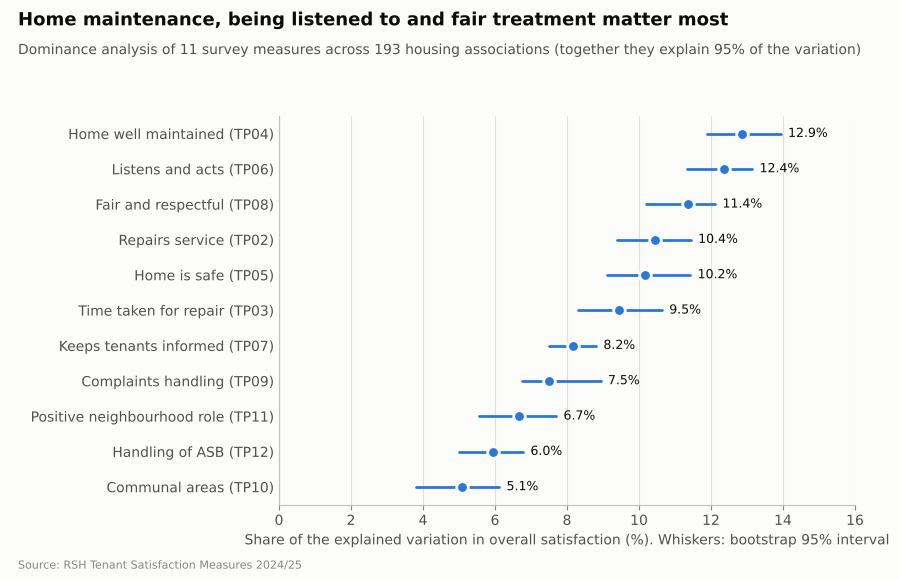

In [9]:
# Sorted smallest first, so the most important ends up at the top.
order = importance.sort_values("share of explained (%)").index
y_pos = np.arange(len(order))

fig, ax = plt.subplots(figsize=(9, 5.8))
fig.subplots_adjust(left=0.31, right=0.95, top=0.80, bottom=0.13)

# Whiskers for the bootstrap interval and dots for the share, all in one colour.
ax.hlines(y_pos, importance.loc[order, "CI low"], importance.loc[order, "CI high"],
          color=HIGHLIGHT, linewidth=2, capstyle="round")
ax.scatter(importance.loc[order, "share of explained (%)"], y_pos, s=70, color=HIGHLIGHT,
           edgecolors=SURFACE, linewidths=2, zorder=3)
# The share written just to the right of each whisker.
for yi, d in zip(y_pos, order):
    ax.text(importance.loc[d, "CI high"] + 0.2, yi, f"{importance.loc[d, 'share of explained (%)']:.1f}%",
            va="center", fontsize=9, color=INK)

ax.set_yticks(y_pos, [f"{labels[d]} ({d})" for d in order])
ax.set_xlim(0, 16)
ax.set_xlabel("Share of the explained variation in overall satisfaction (%). Whiskers: bootstrap 95% interval")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)

titles(fig, "Home maintenance, being listened to and fair treatment matter most",
       f"Dominance analysis of {len(drivers)} survey measures across {len(data)} housing associations "
       f"(together they explain {full_r2:.0%} of the variation)")
fig.savefig("charts/17_key_drivers.png", dpi=200)
plt.show()

### Chart 18: The sector's priority matrix

Each measure is placed by its **importance** (across) and the **sector median** (up means more tenants satisfied). The grey lines are the median importance and the median score, which split the chart into four areas. The bottom-right area (important, and scoring low) is where the biggest opportunities are.

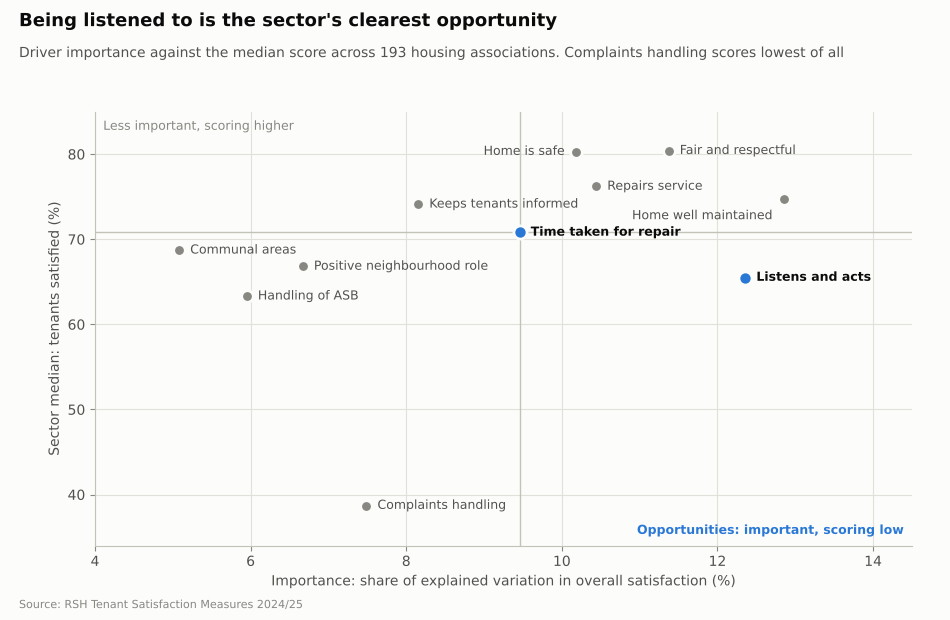

In [10]:
fig, ax = plt.subplots(figsize=(9.5, 6.2))
fig.subplots_adjust(left=0.10, right=0.96, top=0.82, bottom=0.12)

# The two dividing lines, at the median importance and the median score.
x_mid = importance["share of explained (%)"].median()
y_mid = importance["sector median"].median()
ax.axvline(x_mid, color=BASELINE, linewidth=1)
ax.axhline(y_mid, color=BASELINE, linewidth=1)

# Measures in the opportunity area (important and scoring low) in blue, the rest in grey.
priority = (importance["share of explained (%)"] >= x_mid) & (importance["sector median"] <= y_mid)
ax.scatter(importance.loc[~priority, "share of explained (%)"], importance.loc[~priority, "sector median"],
           s=70, color=MUTED, edgecolors=SURFACE, linewidths=2, zorder=3)
ax.scatter(importance.loc[priority, "share of explained (%)"], importance.loc[priority, "sector median"],
           s=90, color=HIGHLIGHT, edgecolors=SURFACE, linewidths=2, zorder=4)

# Label every point. Some labels overlapped, so I nudged them by hand: {code: (x offset, y offset)}.
nudges = {"TP05": (-8, 0), "TP04": (-8, -12)}
for d in importance.index:
    dx, dy = nudges.get(d, (8, 0))
    ax.annotate(labels[d], (importance.loc[d, "share of explained (%)"], importance.loc[d, "sector median"]),
                xytext=(dx, dy), textcoords="offset points", ha="right" if dx < 0 else "left", va="center",
                fontsize=9, fontweight="bold" if priority[d] else "normal", color=INK if priority[d] else INK_2)

# Labels in the corners for the two areas that matter most.
ax.text(0.99, 0.02, "Opportunities: important, scoring low", transform=ax.transAxes, ha="right", va="bottom",
        fontsize=9, color=HIGHLIGHT, fontweight="bold")
ax.text(0.01, 0.98, "Less important, scoring higher", transform=ax.transAxes, ha="left", va="top",
        fontsize=9, color=MUTED)

ax.set_xlim(4, 14.5)
ax.set_ylim(34, 85)
ax.set_xlabel("Importance: share of explained variation in overall satisfaction (%)")
ax.set_ylabel("Sector median: tenants satisfied (%)")

titles(fig, "Being listened to is the sector's clearest opportunity",
       f"Driver importance against the median score across {len(data)} housing associations. Complaints handling scores lowest of all")
fig.savefig("charts/18_priority_matrix.png", dpi=200)
plt.show()

**Listens and acts** sits clearly in the opportunity area: it's important and scores low. **Time taken for repair** sits exactly on both median lines, so it's borderline. **Complaints handling** scores far lower than anything else, but sits just to the left of the importance line.

## What I found

- **Home well maintained, listens and acts, and fair and respectful** are the strongest drivers of overall satisfaction across housing associations. The top two are in the top three in every bootstrap run.
- **Ordinary regression gives misleading answers** here (negative effects for measures that clearly go with higher satisfaction), because the 11 measures overlap so much. Dominance analysis splits the credit fairly.
- **For the sector, being listened to is the clearest opportunity**: it's the second most important driver, and only 65.5% of tenants are satisfied at a typical landlord. **Complaints handling** has the most room to improve of anything (a median of 38.7%).
- This fits with the rest of the project: the operational measures explain a lot but not everything, and the biggest lever the survey points to is **how tenants feel they're treated and heard**.

**Limitations:**
- **Landlord-level data.** I'm using each landlord's average scores, so this shows which measures move together *across landlords*. A key driver analysis on individual tenants' responses (which each landlord holds internally) would be stronger.
- **Derived, not stated, importance.** It shows which measures go with overall satisfaction, not what tenants say matters to them, and correlation still isn't causation.
- **Halo effect.** Tenants who are unhappy overall tend to rate everything lower, which inflates the overlap and the 95% R-squared.